### Bay-to-Bay

In [1]:
Jobs_in = {
    'in_1': {'o': 0,  'd': 20},
    'in_2': {'o': 30, 'd': 10},
    'in_3': {'o': 3,  'd': 18},
    'in_4': {'o': 27, 'd': 12},
}

Jobs_out = {
    'out_1': {'o': 14, 'd': 0,  'r_c': 3},
    'out_2': {'o': 16, 'd': 30, 'r_c': 3},
    'out_3': {'o': 12, 'd': 28, 'r_c': 2},
    'out_4': {'o': 18, 'd': 2,  'r_c': 2},
    'out_5': {'o': 5,  'd': 25, 'r_c': 0},
    'out_6': {'o': 25, 'd': 5,  'r_c': 0},
}

In [2]:
Bay = list(range(30))

Crane = {
    "C1": {"initial": 0},
    "C2": {"initial": 30}
}


# # 1. 분리된 작업 데이터 입력

# Jobs_in = {
#     'in_1' : {'o' : 0, 'd' : 2},
#     'in_2' : {'o' : 6, 'd' : 3},
#     # 'in_3' : {'o' : 0, 'd' : 1}
# }

# Jobs_out = {
#     'out_1' : {'o' : 4, 'd' : 10, 'r_c' : 1},
#     'out_2' : {'o' : 5, 'd' : 0,  'r_c' : 2},
#     # 'out_3' : {'o' : 2, 'd' : 6,  'r_c' : 0},
#     # 'out_4' : {'o' : 3, 'd' : 0,  'r_c' : 2}
# }


# 2. Tasks 병합 및 Rehandle 개별 작업 생성

Tasks = {}
Precedence_Set = []  # (선행 작업, 후행 작업) 쌍을 담을 리스트

# 반입 작업 추가
for j_id, data in Jobs_in.items():
    Tasks[j_id] = {'o': data['o'], 'd': data['d'], 'a': 0, 'b': 300}

# 반출 작업 및 Rehandle 작업 추가
for j_id, data in Jobs_out.items():
    # 본 작업(반출) 추가
    Tasks[j_id] = {'o': data['o'], 'd': data['d'], 'a': 0, 'b': 300}
    
    # Rehandle 컨테이너가 있을 경우
    rc_count = data.get('r_c', 0)
    if rc_count > 0:
        prev_task = None
        for k in range(rc_count):
            rehandle_id = f"{j_id}_r{k+1}"
            # Rehandle은 제자리 작업이므로 o와 d가 반출 작업의 출발지(o)와 동일
            Tasks[rehandle_id] = {'o': data['o'], 'd': data['o'], 'a': 0, 'b': 300}
            
            # 선행 관계 묶어주기 
            if prev_task is not None:
                Precedence_Set.append((prev_task, rehandle_id))
            prev_task = rehandle_id
            
        # 가장 마지막 Rehandle 작업은 반드시 본 작업(j_id)보다 선행되어야 함 (r_last -> 본 작업)
        Precedence_Set.append((prev_task, j_id))

print("\n[Precedence Set]")
print(Precedence_Set)

# print(Tasks)

# 3. Parameter 설정 및 Duration 계산
safety_margin = 1
t_hat = 1
pick = 1
drop = 1
Lambda = pick
h = pick + drop
BigM = 500




[Precedence Set]
[('out_1_r1', 'out_1_r2'), ('out_1_r2', 'out_1_r3'), ('out_1_r3', 'out_1'), ('out_2_r1', 'out_2_r2'), ('out_2_r2', 'out_2_r3'), ('out_2_r3', 'out_2'), ('out_3_r1', 'out_3_r2'), ('out_3_r2', 'out_3'), ('out_4_r1', 'out_4_r2'), ('out_4_r2', 'out_4')]


### Data

In [3]:
# Bay = list(range(31))

# print(Bay)

# Crane = {
#     "C1": {"initial": 0},
#     "C2": {"initial": 30}
# }

# Tasks = {
#     "Task_1":  {"o": 2,  "d": 10, "a": 0, "b": 300},
#     "Task_2":  {"o": 28, "d": 18, "a": 0, "b": 300},
#     "Task_3":  {"o": 5,  "d": 15, "a": 0, "b": 300},
#     "Task_4":  {"o": 25, "d": 12, "a": 0, "b": 300},
#     "Task_5":  {"o": 10, "d": 20, "a": 0, "b": 300},
#     "Task_6":  {"o": 20, "d": 5,  "a": 0, "b": 300},
#     "Task_7":  {"o": 8,  "d": 22, "a": 0, "b": 300},
#     "Task_8":  {"o": 22, "d": 8,  "a": 0, "b": 300},
#     "Task_9":  {"o": 15, "d": 28, "a": 0, "b": 300},
#     "Task_10": {"o": 12, "d": 2,  "a": 0, "b": 300},
#     "Task_11": {"o": 3,  "d": 25, "a": 0, "b": 300},
#     "Task_12": {"o": 27, "d": 4,  "a": 0, "b": 300}
# }

### Parameter

In [4]:
# a, b time window 뽑기
a = {}
b = {}

for i, i_data in Tasks.items():
    a_val = i_data['a']
    b_val = i_data['b']
    
    a[i] = a_val
    b[i] = b_val

print(a)
print(b)

# 작업 내의 duration (h) 계산
duration = {}
for task_number, task_data in Tasks.items():
    o_val = task_data['o']
    d_val = task_data['d']

    # Rehandle 작업(_r)인 경우 이동거리가 0이므로 고정 시간 3 부여
    if "_r" in task_number:
        duration[task_number] = 3
    # 일반 반입/반출 작업인 경우 기존 공식 그대로 사용
    else:
        move_time = abs(o_val - d_val) * t_hat + h
        duration[task_number] = move_time

# 확인용 출력
print("\n[Calculated Duration]")
for k, v in duration.items():
    print(f"{k}: {v}")

# 두 작업끼리의 이동시간 (t)
travel_jobs = {}
for i, i_data in Tasks.items():
    for j, j_data in Tasks.items():
        # 동일한 작업끼리의 이동은 제외 
        if i == j:
            continue
        d_val_i = i_data['d']
        o_val_j = j_data['o']
        travel_time = abs(d_val_i - o_val_j) * t_hat
        
        # (출발 작업, 도착 작업)을 Key 값으로 저장
        travel_jobs[i, j] = travel_time

# print(travel_jobs)

# 각 Crane의 초기 위치 뽑고 index로 표현 
crane_initial = {}
for Crane_number, Crane_data in Crane.items():
    initial = Crane_data["initial"]
    crane_initial[Crane_number] = initial
print(crane_initial)

# 각 크레인의 초기 위치에서 작업 t 시작 위치까지의 이동 시간
initial_CM = {}
for i in Tasks:
    for v in Crane:
        task_o_val = Tasks[i]['o']
        crane_position = crane_initial[v]
        initial_move_time = abs(crane_position - task_o_val) * t_hat
        
        # (크레인, 작업)을 Key 값으로 저장
        initial_CM[v, i] = initial_move_time

print(initial_CM)

sort_crane = sorted(crane_initial.items(), key=lambda x: x[1]) # value 값을 기준으로 정렬
crane_index = {k[0]: idx for idx, k in enumerate(sort_crane, start=1)}

# print(sort_crane)
# print(crane_index)

# delta 만들기
delta = {}
for v in Crane:
    for w in Crane:
        delta[v, w] = (safety_margin + 1) * abs(crane_index[v] - crane_index[w])

# print(delta)

{'in_1': 0, 'in_2': 0, 'in_3': 0, 'in_4': 0, 'out_1': 0, 'out_1_r1': 0, 'out_1_r2': 0, 'out_1_r3': 0, 'out_2': 0, 'out_2_r1': 0, 'out_2_r2': 0, 'out_2_r3': 0, 'out_3': 0, 'out_3_r1': 0, 'out_3_r2': 0, 'out_4': 0, 'out_4_r1': 0, 'out_4_r2': 0, 'out_5': 0, 'out_6': 0}
{'in_1': 300, 'in_2': 300, 'in_3': 300, 'in_4': 300, 'out_1': 300, 'out_1_r1': 300, 'out_1_r2': 300, 'out_1_r3': 300, 'out_2': 300, 'out_2_r1': 300, 'out_2_r2': 300, 'out_2_r3': 300, 'out_3': 300, 'out_3_r1': 300, 'out_3_r2': 300, 'out_4': 300, 'out_4_r1': 300, 'out_4_r2': 300, 'out_5': 300, 'out_6': 300}

[Calculated Duration]
in_1: 22
in_2: 22
in_3: 17
in_4: 17
out_1: 16
out_1_r1: 3
out_1_r2: 3
out_1_r3: 3
out_2: 16
out_2_r1: 3
out_2_r2: 3
out_2_r3: 3
out_3: 18
out_3_r1: 3
out_3_r2: 3
out_4: 18
out_4_r1: 3
out_4_r2: 3
out_5: 22
out_6: 22
{'C1': 0, 'C2': 30}
{('C1', 'in_1'): 0, ('C2', 'in_1'): 30, ('C1', 'in_2'): 30, ('C2', 'in_2'): 0, ('C1', 'in_3'): 3, ('C2', 'in_3'): 27, ('C1', 'in_4'): 27, ('C2', 'in_4'): 3, ('C1', 'ou

### Set

In [5]:

# 작업 key 집합
Set_T = list(Tasks.keys())
print(Set_T)

# 크레인 key 집합
Set_V = list(Crane.keys())
print(Set_V)

# 각 작업의 l_min, l_max 뽑아주기
task_interval = {}
for t, data in Tasks.items():
    l_min = min(data["o"], data["d"])
    l_max = max(data["o"], data["d"])
    task_interval[t] = {"l_min": l_min, "l_max": l_max}

print(task_interval)

# 충돌 잠재쌍 집합
Theta = []

for t in Set_T:
    for tp in Set_T:
        if t == tp:
            continue

        l_tau_min = task_interval[t]["l_min"]
        l_tau_max = task_interval[t]["l_max"]

        l_tau_p_min = task_interval[tp]["l_min"]
        l_tau_p_max = task_interval[tp]["l_max"]

        for v in Set_V:
            for w in Set_V:
                if v == w:
                    continue

                # crane index 순서 비교
                if crane_index[v] < crane_index[w]:
                    # v가 아래, w가 위
                    if l_tau_max + delta[v, w] > l_tau_p_min:
                        Theta.append((t, tp, v, w))

                elif crane_index[v] > crane_index[w]:
                    # v가 위, w가 아래
                    if l_tau_min - delta[v, w] < l_tau_p_max:
                        Theta.append((t, tp, v, w))

print(Theta)

['in_1', 'in_2', 'in_3', 'in_4', 'out_1', 'out_1_r1', 'out_1_r2', 'out_1_r3', 'out_2', 'out_2_r1', 'out_2_r2', 'out_2_r3', 'out_3', 'out_3_r1', 'out_3_r2', 'out_4', 'out_4_r1', 'out_4_r2', 'out_5', 'out_6']
['C1', 'C2']
{'in_1': {'l_min': 0, 'l_max': 20}, 'in_2': {'l_min': 10, 'l_max': 30}, 'in_3': {'l_min': 3, 'l_max': 18}, 'in_4': {'l_min': 12, 'l_max': 27}, 'out_1': {'l_min': 0, 'l_max': 14}, 'out_1_r1': {'l_min': 14, 'l_max': 14}, 'out_1_r2': {'l_min': 14, 'l_max': 14}, 'out_1_r3': {'l_min': 14, 'l_max': 14}, 'out_2': {'l_min': 16, 'l_max': 30}, 'out_2_r1': {'l_min': 16, 'l_max': 16}, 'out_2_r2': {'l_min': 16, 'l_max': 16}, 'out_2_r3': {'l_min': 16, 'l_max': 16}, 'out_3': {'l_min': 12, 'l_max': 28}, 'out_3_r1': {'l_min': 12, 'l_max': 12}, 'out_3_r2': {'l_min': 12, 'l_max': 12}, 'out_4': {'l_min': 2, 'l_max': 18}, 'out_4_r1': {'l_min': 18, 'l_max': 18}, 'out_4_r2': {'l_min': 18, 'l_max': 18}, 'out_5': {'l_min': 5, 'l_max': 25}, 'out_6': {'l_min': 5, 'l_max': 25}}
[('in_1', 'in_2', '

### ETD (Extend Temporal Distance)

In [6]:
def compute_etd_paper(t, tp, v, w, Tasks, delta, crane_index, t_hat, Lambda):
    l1_t  = Tasks[t]["o"]
    l2_t  = Tasks[t]["d"]
    l1_tp = Tasks[tp]["o"]
    l2_tp = Tasks[tp]["d"]
    d = delta[(v, w)]
    # case 1
    if crane_index[v] < crane_index[w]:
        base = (l2_t + d - l1_tp) * t_hat
        C11 = (l2_t + d > l1_tp)
        C12 = (l1_t + d > l1_tp)
        C13 = (l2_t + d > l2_tp)

        if C11:
            return base, "Case1-C1.1"
        elif C12 or C13:
            return base - Lambda, "Case1-C1.2/C1.3"
        else:
            return base - 2 * Lambda, "Case1-otherwise"
    # case 2
    elif crane_index[v] > crane_index[w]:
        base = (l1_tp - l2_t + d) * t_hat
        C21 = (l2_t - d < l1_tp)
        C22 = (l1_t - d < l1_tp)
        C23 = (l2_t - d < l2_tp)

        if C21:
            return base, "Case2-C2.1"
        elif C22 or C23:
            return base - Lambda, "Case2-C2.2/C2.3"
        else:
            return base - 2 * Lambda, "Case2-otherwise"

    else:
        raise ValueError("동일한 크레인은 허용되지 않음")

# ETD 딕셔너리 형태로 저장
ETD = {}
for t, tp, v, w in Theta: # Theta 집합 : 충돌 가능성이 있는 집합 안에서 ETD 계산해주기
    etd_val, case_name = compute_etd_paper(
        t, tp, v, w, Tasks, delta, crane_index, t_hat, Lambda
    )
    ETD[(t, tp, v, w)] = etd_val
    #print((t, tp, v, w), "->", etd_val, case_name)

# print(ETD)

### Decision Variables

In [7]:
import gurobipy as gp
from gurobipy import GRB

model = gp.Model("Kaist")

# Binary 변수 정의
x = model.addVars(Set_T, Set_V, vtype=GRB.BINARY, name="x_iv")
y = model.addVars(Set_T, Set_T, Set_V, vtype=GRB.BINARY, name="y_ijv")
z = model.addVars(Set_T, Set_T, vtype=GRB.BINARY, name="z_ij")

# Interger 변수 정의
s = model.addVars(Set_T, vtype=GRB.CONTINUOUS, lb=0, name="s_i")
# f = model.addVars(Set_T, vtype=GRB.CONTINUOUS, lb=0, name="f_i")

# Makespan을 위한 단일 변수 선언
makespan = model.addVar(vtype=GRB.CONTINUOUS, name="makespan")


Set parameter Username
Set parameter LicenseID to value 2795050
Academic license - for non-commercial use only - expires 2027-03-20


### 수리모형

In [8]:

# 목적함수 makespan 최소화
model.setObjective(makespan, GRB.MINIMIZE)

# 제약식
for i in Set_T:
    model.addConstr(
        gp.quicksum(x[i,v] for v in Set_V)== 1, name = '3'
    )

for v in Set_V:
    for i in Set_T:
        model.addConstr(
            initial_CM[v,i] <= s[i] + BigM * (1-x[i,v]), name = "4"
        )

    for i in Set_T:
        for j in Set_T:
            if i == j:
                continue
            model.addConstr(
                x[i,v] + x[j,v] - 1 <= y[i,j,v] + y[j,i,v], name= "5"
            )

for v in Set_V:
    for i in Set_T:
        for j in Set_T:
            if i == j:
                continue
            model.addConstr(
                s[i] + duration[i] + travel_jobs[i,j] <= s[j] + BigM * (1-y[i,j,v]), name= "6"
            )

for (i,j,v,w) in Theta:
    model.addConstr(
        x[i,v] + x[j,w] - 1 <= z[i,j] + z[j,i], name= "7"
    )

for (i,j,v,w) in Theta:
    model.addConstr(
        s[i] + duration[i] + ETD[i,j,v,w] <= s[j] + BigM * (3 - z[i,j] - x[i,v] - x[j,w]), name= "8"
    )

for i in Set_T:
    model.addConstr(
        a[i] <= s[i], name = '9'
    )

for i in Set_T:
    model.addConstr(
        s[i] <= b[i], name = '10'
    )

for i in Set_T:
    model.addConstr(
        makespan >= s[i] + duration[i], name = '12'
    )

# 선행관계 (rehandle, 반출)
for (i, j) in Precedence_Set:
    model.addConstr(
        s[i] + duration[i] <= s[j], 
        name=f"prec_{i}_{j}"
    )

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (mac64[arm] - Darwin 25.6.0 25G83)

CPU model: Apple M3
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
TimeLimit  300

Optimize a model with 2978 rows, 1261 columns and 11516 nonzeros (Min)
Model fingerprint: 0xc56ef5c2
Model has 1 linear objective coefficients
Variable types: 21 continuous, 1240 integer (1240 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+02]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+03]

Presolve removed 869 rows and 129 columns
Presolve time: 0.02s
Presolved: 2109 rows, 1132 columns, 8296 nonzeros
Variable types: 21 continuous, 1111 integer (1111 binary)

Root relaxation: objective 3.900000e+01, 740 iterations, 0.01 seconds (0.03 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Une

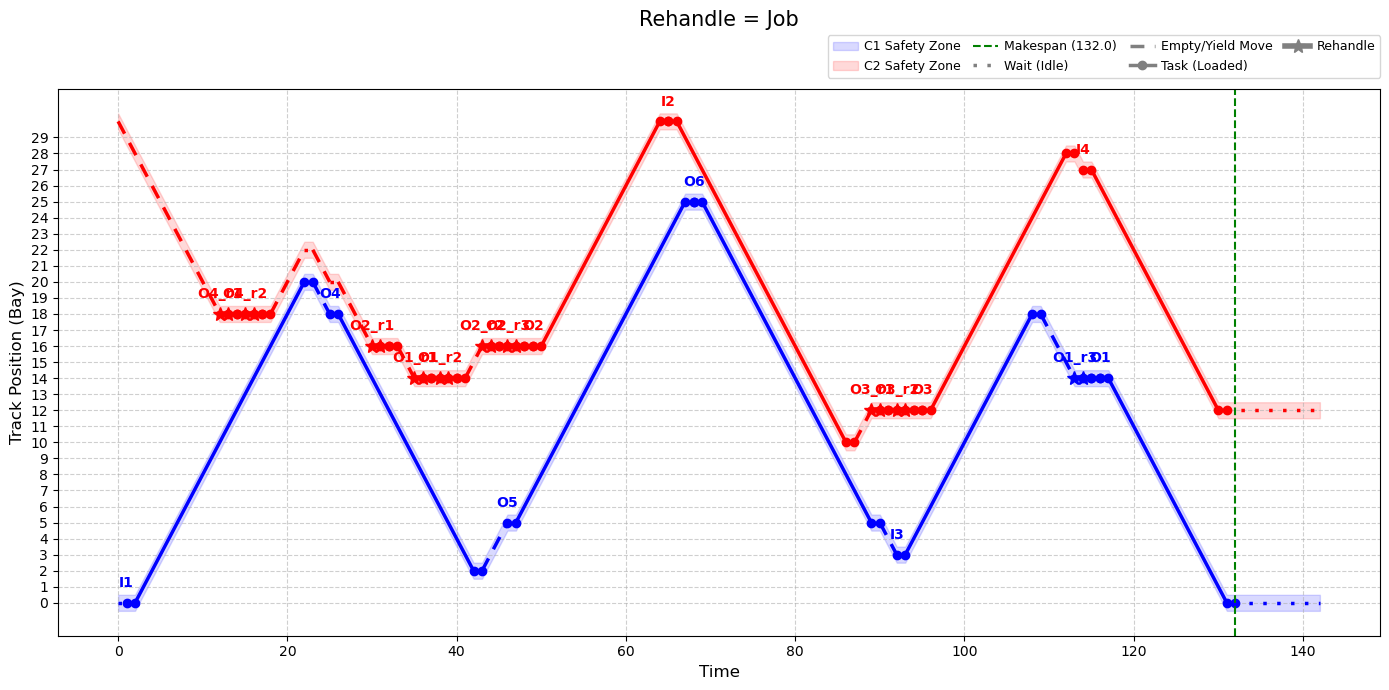

In [9]:
# =========================
# Solve
# =========================
model.Params.OutputFlag = 1      # 로그 출력
model.Params.TimeLimit = 300     # 타임리미트 설정 (예: 300초)

model.optimize()

# =========================
# Result Extraction
# =========================
# 🌟 핵심: 타임리미트에 도달했더라도 피저블 해가 1개 이상(SolCount > 0) 존재하면 결과 출력
if model.SolCount > 0:
    print("\n==============================")
    print("Optimization Result")
    print("==============================")
    
    if model.Status == GRB.OPTIMAL:
        print("Status      : OPTIMAL (최적해를 찾음)")
    elif model.Status == GRB.TIME_LIMIT:
        print("Status      : TIME_LIMIT (시간 초과! 현재까지 찾은 피저블 해 출력)")
    else:
        print(f"Status      : SUBOPTIMAL / FEASIBLE (Code: {model.Status})")

    print(f"Objective (Makespan) = {makespan.X:.2f}")

    # 작업별 결과 저장
    result_rows = []
    for i in Set_T:
        assigned_crane = None
        for v in Set_V:
            if x[i, v].X > 0.5:
                assigned_crane = v
                break
        
        start_time = s[i].X
        completion_time = start_time + duration[i]

        result_rows.append({
            "task": i,
            "crane": assigned_crane,
            "origin": Tasks[i]["o"],
            "destination": Tasks[i]["d"],
            "start": start_time,
            "duration": duration[i],
            "completion": completion_time
        })

    # 시작시간 기준 정렬
    result_rows = sorted(result_rows, key=lambda r: r["start"])

    print("\n[Task Schedule]")
    for row in result_rows:
        print(
            f"{row['task']:>8} | Crane={row['crane']:>2} | "
            f"o={row['origin']:>2} -> d={row['destination']:>2} | "
            f"start={row['start']:>6.2f} | dur={row['duration']:>6.2f} | "
            f"end={row['completion']:>6.2f}"
        )

    print("\n[Crane-wise Sequence]")
    for v in Set_V:
        crane_tasks = [r for r in result_rows if r["crane"] == v]
        crane_tasks = sorted(crane_tasks, key=lambda r: r["start"])

        print(f"\nCrane {v}")
        if not crane_tasks:
            print("  No assigned tasks")
            continue

        for idx, row in enumerate(crane_tasks, start=1):
            print(
                f"  {idx:>2}. {row['task']} "
                f"(start={row['start']:.2f}, end={row['completion']:.2f}, "
                f"o={row['origin']}, d={row['destination']})"
            )
                
    import math
    import matplotlib.pyplot as plt
    import matplotlib.lines as mlines

    # =========================
    # Visualization
    # =========================
    plt.figure(figsize=(14, 7))
    crane_colors = {"C1": "blue", "C2": "red"}

    max_t = int(math.ceil(makespan.X)) + 10
    time_arr = list(range(max_t + 1))
    y = {v: [float(crane_initial[v])] * (max_t + 1) for v in Set_V}
    state = {v: ['idle'] * (max_t + 1) for v in Set_V}

    sorted_cranes = sorted(Set_V, key=lambda v: crane_index[v])
    c_bottom = sorted_cranes[0]  
    c_top = sorted_cranes[1]     
    delta_val = delta[(c_bottom, c_top)]

    for v in Set_V:
        tasks = [r for r in result_rows if r["crane"] == v]
        for task in tasks:
            start_t = int(round(task["start"]))
            dur = int(round(task["duration"]))
            o_loc = task["origin"]
            d_loc = task["destination"]
            
            travel_time = abs(o_loc - d_loc) * t_hat
            rehandle_dur = dur - (pick + drop + travel_time)
            
            curr_time = start_t
            
            if rehandle_dur > 0:
                for t in range(curr_time, curr_time + rehandle_dur):
                    if t <= max_t:
                        y[v][t] = float(o_loc)
                        state[v][t] = 'active'
                curr_time += rehandle_dur
                
            for t in range(curr_time, curr_time + pick):
                if t <= max_t:
                    y[v][t] = float(o_loc)
                    state[v][t] = 'active'
            curr_time += pick
            
            arr_time = curr_time + travel_time
            step = 1.0 if d_loc > o_loc else -1.0
            curr_y = float(o_loc)
            for t in range(curr_time, arr_time + 1):
                if t <= max_t:
                    y[v][t] = curr_y
                    state[v][t] = 'active'
                if t < arr_time: curr_y += step
            curr_time = arr_time
            
            for t in range(curr_time, start_t + dur + 1):
                if t <= max_t:
                    y[v][t] = float(d_loc)
                    state[v][t] = 'active'

    for v in Set_V:
        tasks = [r for r in result_rows if r["crane"] == v]
        if not tasks: continue
        
        first_start = int(round(tasks[0]["start"]))
        loc_first = tasks[0]["origin"]
        dist_first = abs(crane_initial[v] - loc_first) * t_hat
        move_start_first = first_start - dist_first
        
        curr_y = float(crane_initial[v])
        step = 1.0 if loc_first > crane_initial[v] else -1.0
        for t in range(max(0, move_start_first), first_start):
            if t <= max_t and state[v][t] == 'idle':
                y[v][t] = curr_y
                curr_y += step
                
        for t in range(0, max(0, move_start_first)):
            if t <= max_t and state[v][t] == 'idle': y[v][t] = float(crane_initial[v])

        for i in range(len(tasks)-1):
            end_prev = int(round(tasks[i]["completion"]))
            start_next = int(round(tasks[i+1]["start"]))
            loc_prev = tasks[i]["destination"]
            loc_next = tasks[i+1]["origin"]
            dist = abs(loc_prev - loc_next) * t_hat
            move_start = start_next - dist
            
            for t in range(end_prev, move_start):
                if t <= max_t and state[v][t] == 'idle': y[v][t] = float(loc_prev)
            
            curr_y = float(loc_prev)
            step = 1.0 if loc_next > loc_prev else -1.0
            for t in range(max(end_prev, move_start), start_next):
                if t <= max_t and state[v][t] == 'idle':
                    y[v][t] = curr_y
                    curr_y += step

        last_end = int(round(tasks[-1]["completion"]))
        loc_last = tasks[-1]["destination"]
        for t in range(last_end, max_t + 1):
            if state[v][t] == 'idle': y[v][t] = float(loc_last)

    for sweep in range(300):
        for t in range(max_t + 1):
            if y[c_bottom][t] > y[c_top][t] - delta_val: 
                if state[c_bottom][t] == 'active' and state[c_top][t] == 'idle':
                    y[c_top][t] = y[c_bottom][t] + delta_val
                elif state[c_top][t] == 'active' and state[c_bottom][t] == 'idle':
                    y[c_bottom][t] = y[c_top][t] - delta_val
                elif state[c_bottom][t] == 'idle' and state[c_top][t] == 'idle':
                    mid = (y[c_bottom][t] + y[c_top][t]) / 2.0
                    y[c_bottom][t] = mid - delta_val / 2.0
                    y[c_top][t] = mid + delta_val / 2.0
        
        for v in Set_V:
            for t in range(1, max_t + 1):
                if state[v][t] == 'idle':
                    if y[v][t] > y[v][t-1] + 1.0: y[v][t] = y[v][t-1] + 1.0
                    if y[v][t] < y[v][t-1] - 1.0: y[v][t] = y[v][t-1] - 1.0
            for t in range(max_t - 1, -1, -1):
                if state[v][t] == 'idle':
                    if y[v][t] > y[v][t+1] + 1.0: y[v][t] = y[v][t+1] + 1.0
                    if y[v][t] < y[v][t+1] - 1.0: y[v][t] = y[v][t+1] - 1.0
        
        for v in Set_V:
            y[v][0] = float(crane_initial[v])

    for v in Set_V:
        upper_bounds = [val + 0.5 for val in y[v]]
        lower_bounds = [val - 0.5 for val in y[v]]
        plt.fill_between(
            time_arr, lower_bounds, upper_bounds,
            color=crane_colors[v],
            alpha=0.15,
            label=f'{v} Safety Zone'
        )

        tasks = [r for r in result_rows if r["crane"] == v]
        for task in tasks:
            start_t = task["start"]
            dur = task["duration"]
            o_loc = task["origin"]
            d_loc = task["destination"]
            
            travel_time = abs(o_loc - d_loc) * t_hat
            rehandle_dur = dur - (pick + drop + travel_time)
            
            curr_time = start_t
            
            if rehandle_dur > 0:
                rehandle_end = curr_time + rehandle_dur
                plt.plot([curr_time, rehandle_end], [o_loc, o_loc], color=crane_colors[v], linestyle='-', linewidth=4.0, marker='*', markersize=10)
                curr_time = rehandle_end
                
            pick_end = curr_time + pick
            plt.plot([curr_time, pick_end], [o_loc, o_loc], color=crane_colors[v], linestyle='-', linewidth=2.5, marker='o')
            
            arr_time = pick_end + travel_time
            plt.plot([pick_end, arr_time], [o_loc, d_loc], color=crane_colors[v], linestyle='-', linewidth=2.5)
            
            finish_time = arr_time + drop
            plt.plot([arr_time, finish_time], [d_loc, d_loc], color=crane_colors[v], linestyle='-', linewidth=2.5, marker='o')

            task_label = str(task["task"]).replace("out_", "O").replace("in_", "I")
            plt.text(start_t, o_loc + 0.8, task_label, fontsize=10, color=crane_colors[v], fontweight='bold', ha='center', va='bottom')

        intervals = []
        for t in range(max_t):
            if state[v][t] == 'active' and state[v][t+1] == 'active':
                intervals.append('active')
            else:
                speed = abs(y[v][t+1] - y[v][t])
                intervals.append('empty' if speed > 0.01 else 'wait')

        start_t = 0
        while start_t < max_t:
            ctype = intervals[start_t]
            if ctype == 'active':
                start_t += 1
                continue
                
            end_t = start_t
            while end_t < max_t and intervals[end_t] == ctype:
                end_t += 1
                
            t_arr = list(range(start_t, end_t + 1))
            y_arr = [y[v][t] for t in t_arr]
            
            if ctype == 'empty':
                plt.plot(t_arr, y_arr, color=crane_colors[v], linestyle='--', dashes=(4, 3), linewidth=2.5)
            elif ctype == 'wait':
                plt.plot(t_arr, y_arr, color=crane_colors[v], linestyle=':', dashes=(1, 3), linewidth=2.5)
                
            start_t = end_t

    if makespan.X > 0:
        plt.axvline(x=makespan.X, color='green', linestyle='--', label=f'Makespan ({makespan.X:.1f})')

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    
    wait_line = mlines.Line2D([], [], color='gray', linestyle=':', dashes=(1, 3), linewidth=2.5, label='Wait (Idle)')
    empty_line = mlines.Line2D([], [], color='gray', linestyle='--', dashes=(4, 3), linewidth=2.5, label='Empty/Yield Move')
    loaded_line = mlines.Line2D([], [], color='gray', linestyle='-', linewidth=2.5, marker='o', label='Task (Loaded)')
    rehandle_line = mlines.Line2D([], [], color='gray', linestyle='-', linewidth=4.0, marker='*', markersize=10, label='Rehandle')

    final_handles = list(by_label.values()) + [wait_line, empty_line, loaded_line, rehandle_line]
    final_labels = list(by_label.keys()) + ['Wait (Idle)', 'Empty/Yield Move', 'Task (Loaded)', 'Rehandle']

    plt.legend(final_handles, final_labels, loc='lower right', bbox_to_anchor=(1.0, 1.02), ncol=4, fontsize=9, columnspacing=1.0, handletextpad=0.5, borderaxespad=0.)
    plt.xlabel("Time", fontsize=12)
    plt.ylabel("Track Position (Bay)", fontsize=12)
    plt.title("Rehandle = Job", fontsize=15, pad=45)
    plt.yticks(Bay) 
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

else:
    # 솔루션을 단 1개도 찾지 못한 경우 출력
    print("\n==============================")
    print("Optimization Result")
    print("==============================")
    print("지정된 시간(TimeLimit) 내에 실행 가능한(Feasible) 스케줄을 단 한 개도 찾지 못했습니다.")
    print(f"Gurobi Status Code = {model.Status}")